## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027神经活动轨迹数据审计.py', 'logs/audit_data/initial/summary.json')
run_long_task('261027分区线性基线.py', 'logs/regional_linear_baselines/initial/model_summary.csv')


复用： logs/audit_data/initial/summary.json
复用： logs/regional_linear_baselines/initial/model_summary.csv


# Episode-aware regional linear baselines

This notebook separates easy prediction of a slowly varying fluorescence level from prediction of the next increment. Models are trained, selected, and tested on chronologically disjoint state episodes.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig

ROOT = Path('..').resolve()
INPUT = ROOT / 'logs/regional_linear_baselines/initial'
OUTPUT = ROOT / 'figures/261027分区线性基线'
OUTPUT.mkdir(parents=True, exist_ok=True)
summary = pd.read_csv(INPUT / 'model_summary.csv')
rollout = pd.read_csv(INPUT / 'rollout_metrics.csv')
summary

,state,history,model,alpha,validation_mse,one_step_r2_flat,one_step_corr_flat,one_step_r2_region_median,one_step_corr_region_median,dx_r2_flat,n_test_targets,pearson_gt_0p5_seconds,r2_gt_0_seconds,rollout_cap_seconds
0,Awake,1,persistence,0.00,0.060872,0.952881,0.976438,0.891658,0.945956,-0.000059,5129,19.294248,19.294248,19.294248
1,Awake,1,self,0.01,0.063797,0.948601,0.976310,0.880246,0.945956,-0.090890,5129,19.294248,3.135315,19.294248
2,Awake,1,self_global,0.01,0.060859,0.951140,0.976297,0.875789,0.945953,-0.037016,5129,6.270630,4.582384,19.294248
3,Awake,1,full_var,1.00,0.060550,0.947549,0.975857,0.874456,0.947713,-0.113224,5129,17.364823,6.752987,19.294248
4,Awake,3,persistence,0.00,0.060832,0.952887,0.976441,0.890369,0.945303,-0.000062,5109,19.294248,19.294248,19.294248
5,Awake,3,self,0.01,0.063019,0.949570,0.976806,0.880645,0.946974,-0.070470,5109,17.123645,3.135315,19.294248
6,Awake,3,self_global,0.01,0.059229,0.953691,0.977621,0.881610,0.947426,0.017013,5109,8.200055,4.341206,19.294248
7,Awake,3,full_var,10.00,0.054143,0.955395,0.979116,0.889847,0.951924,0.053176,5109,19.294248,10.129480,19.294248
8,Awake,10,persistence,0.00,0.061025,0.952834,0.976415,0.887973,0.944035,-0.000074,5039,19.294248,19.294248,19.294248
9,Awake,10,self,0.01,0.061459,0.951091,0.976960,0.884369,0.945633,-0.037018,5039,19.294248,5.305918,19.294248


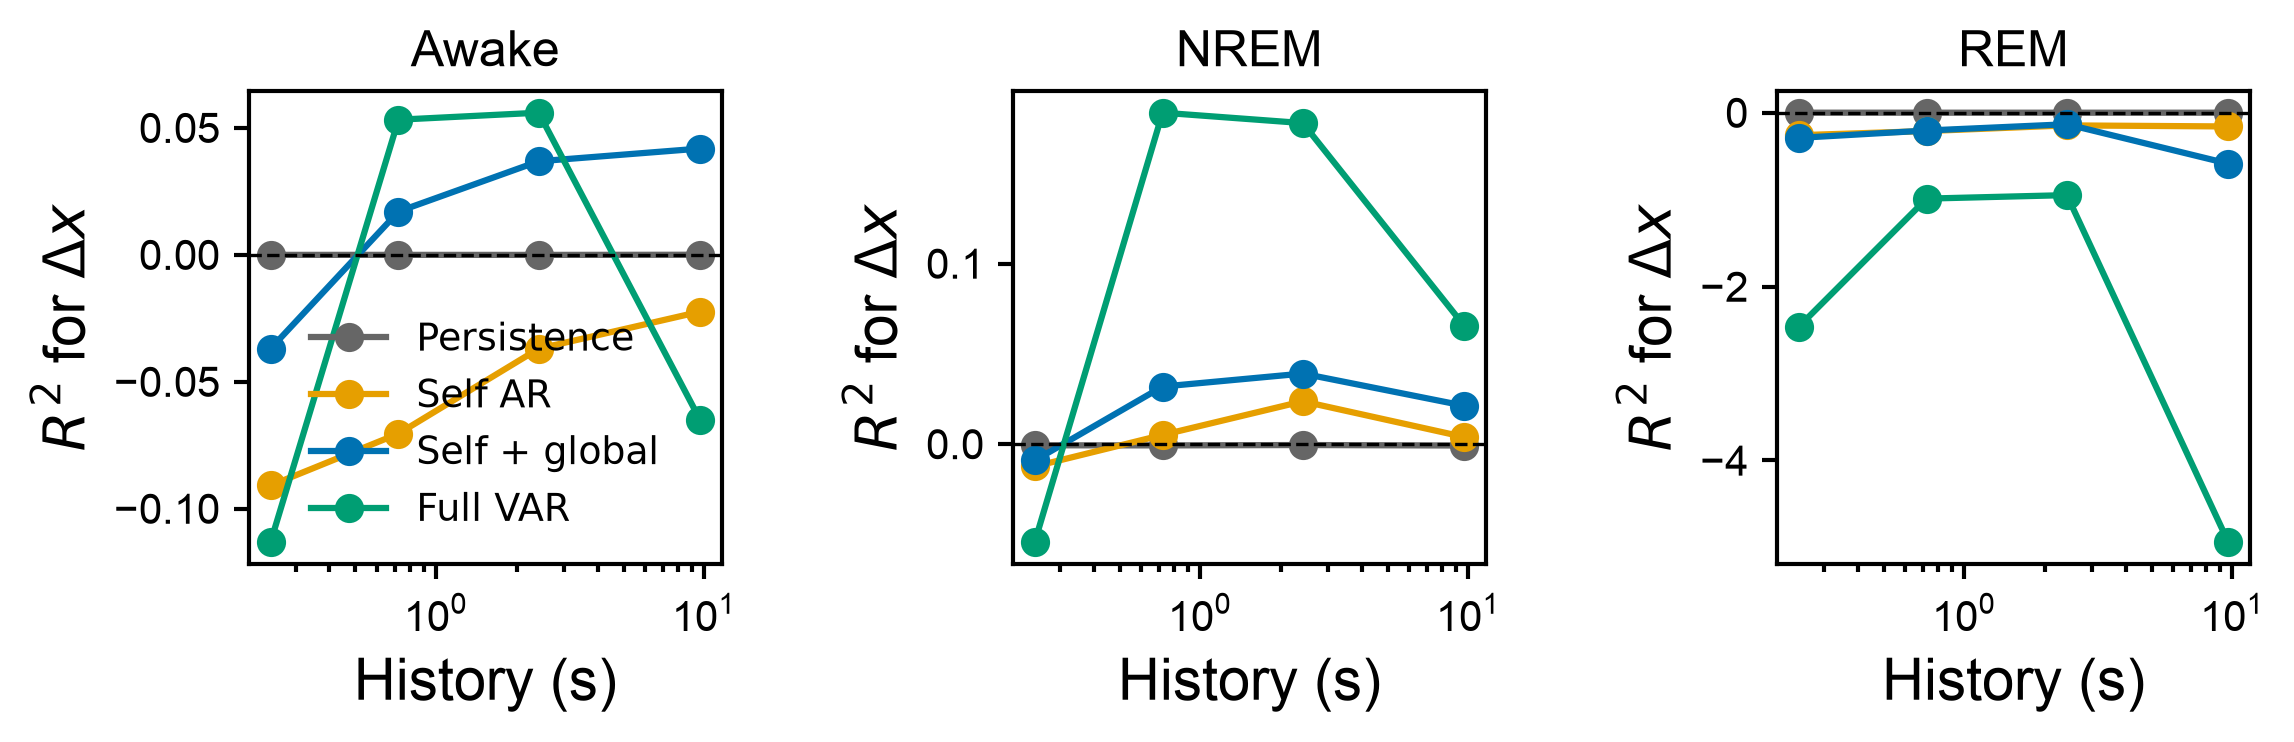

In [3]:
states = ['Awake', 'NREM', 'REM']
models = ['persistence', 'self', 'self_global', 'full_var']
labels = {'persistence': 'Persistence', 'self': 'Self AR', 'self_global': 'Self + global', 'full_var': 'Full VAR'}
colors = {'persistence': '#666666', 'self': '#E69F00', 'self_global': '#0072B2', 'full_var': '#009E73'}
fig, axes = get_fig(RN=1, CN=3, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(np.asarray(axes).reshape(-1))
for state in states:
    ax = next(ax_loader)
    part = summary[summary.state == state]
    for model in models:
        group = part[part.model == model].sort_values('history')
        ax.plot(group.history / 4.146313525439001, group.dx_r2_flat, marker='o', color=colors[model], label=labels[model])
    ax.axhline(0, color='black', ls='--', lw=0.8)
    ax.set_xscale('log')
    ax.set_xlabel('History (s)')
    ax.set_ylabel(r'$R^2$ for $\Delta x$')
    ax.set_title(state)
    if state == 'Awake':
        ax.legend(frameon=False, fontsize=9)
for suffix in ('png', 'svg', 'pdf'):
    fig.savefig(OUTPUT / f'increment_prediction.{suffix}', bbox_inches='tight', transparent=True)
plt.show()

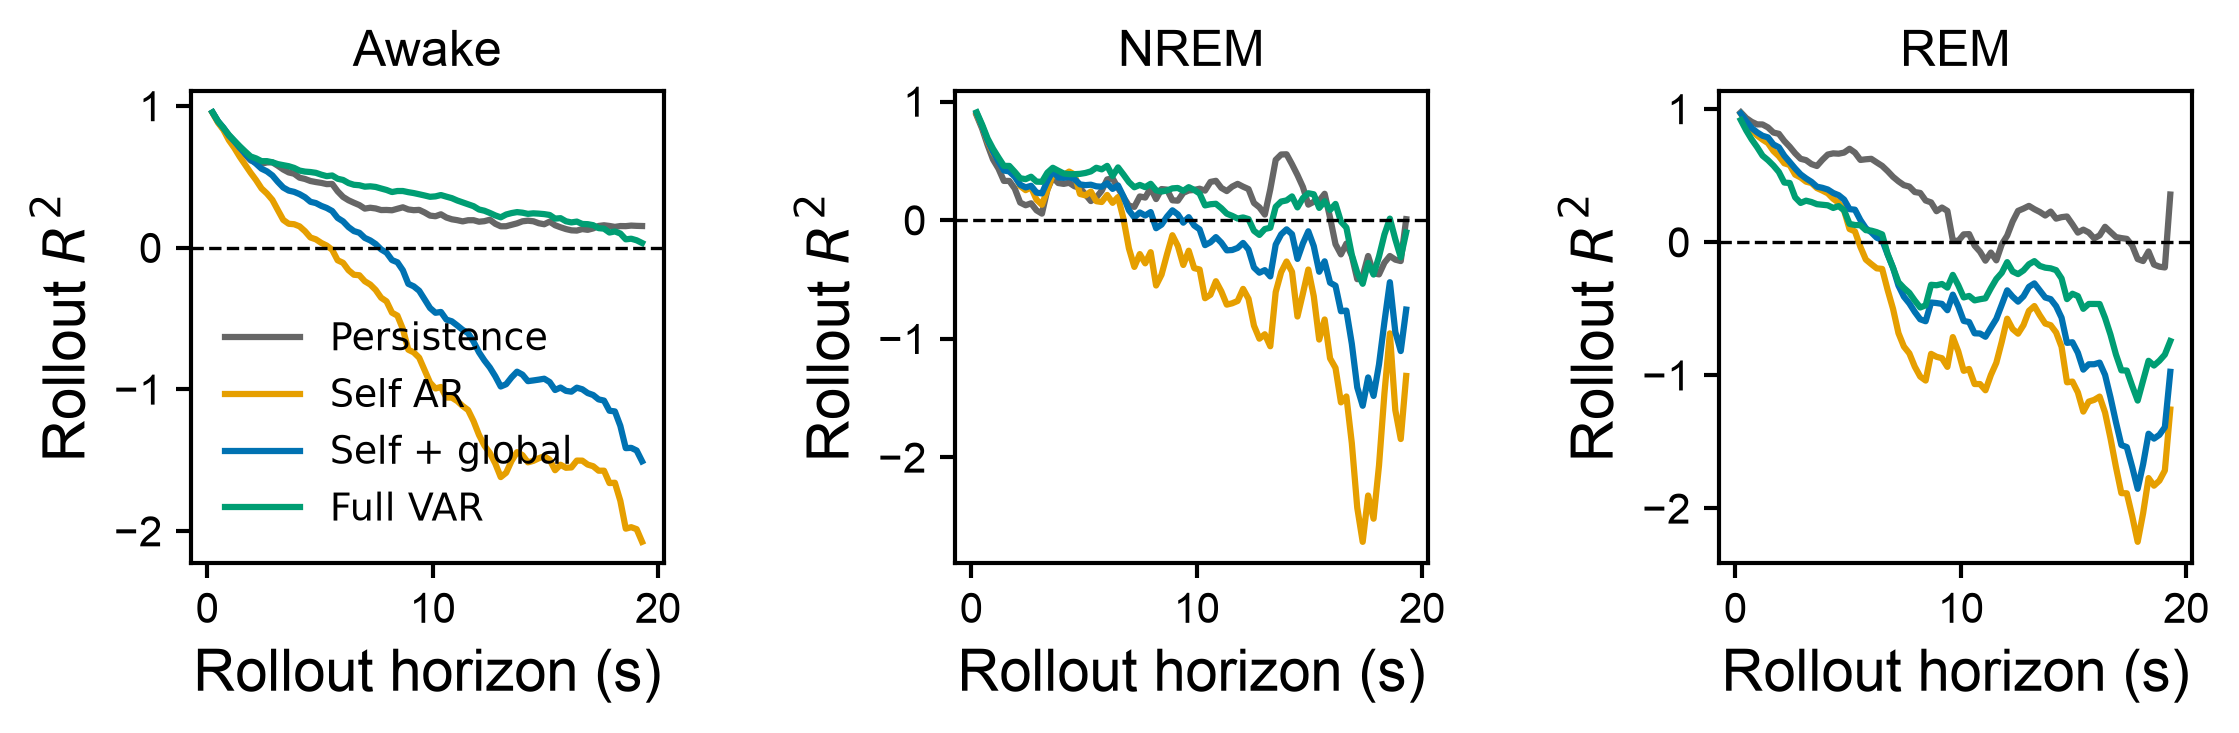

In [4]:
fig, axes = get_fig(RN=1, CN=3, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(np.asarray(axes).reshape(-1))
for state in states:
    ax = next(ax_loader)
    part = rollout[(rollout.state == state) & (rollout.history == 10)]
    for model in models:
        group = part[part.model == model].sort_values('seconds')
        ax.plot(group.seconds, group.r2_flat, color=colors[model], label=labels[model])
    ax.axhline(0, color='black', ls='--', lw=0.8)
    ax.set_xlabel('Rollout horizon (s)')
    ax.set_ylabel(r'Rollout $R^2$')
    ax.set_title(state)
    if state == 'Awake':
        ax.legend(frameon=False, fontsize=9)
for suffix in ('png', 'svg', 'pdf'):
    fig.savefig(OUTPUT / f'rollout_r2_history10.{suffix}', bbox_inches='tight', transparent=True)
plt.show()

## Interpretation

Raw one-step level prediction is dominated by persistence and is therefore not a discriminating model test. Increment prediction shows modest added information from cross-region history in Awake and clearer added information in NREM. REM has only five episodes (3/1/1 train/validation/test), so fitted cross-region models are not identifiable and generalize worse than persistence. None of these predictive gains establishes directed effective connectivity.